# 02 · Analisi del test finale held-out

## Music Discovery CMAB — Last.fm 1K

Analisi delle **cinque configurazioni congelate sulla validation**. Il notebook verifica manifesto, configurazione, aggregati e checkpoint, poi confronta il test con i run selezionati a N=100. Non effettua selezione o tuning sul test.

Le metriche mantengono il cutoff esplicito `@5`, `@10` o `@20`. Nei CSV, `catalog_coverage` e `artist_coverage` senza suffisso sono alias di @20. I JSONL grandi vengono verificati con hashing a blocchi; non sono caricati in memoria.

In [1]:
from __future__ import annotations
import hashlib,json,math
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

def root_from(path=None):
    p=(path or Path.cwd()).resolve()
    for q in (p,*p.parents):
        if (q/'experiments/configs/final_test.json').is_file(): return q
    raise FileNotFoundError('Repository root not found')
def sha256(path,chunk=8*1024*1024):
    h=hashlib.sha256()
    with Path(path).open('rb') as f:
        while b:=f.read(chunk): h.update(b)
    return h.hexdigest()
ROOT=root_from(); MANIFEST=ROOT/'experiments/configs/final_selection_manifest.json'
CONFIG=ROOT/'experiments/configs/final_test.json'
TEST=ROOT/'experiments/results/test/044f9269d4e3-5b076e7a'
VAL=ROOT/'experiments/results/validation/ea8616724509-5b076e7a'
CP=ROOT/'experiments/results/checkpoints/final-test-044f9269d4e3-5b076e7a1cb3'
TEST_CSV=TEST/'runs.csv'; TEST_JSONL=TEST/'runs.jsonl'; VAL_CSV=VAL/'runs.csv'
EXPECTED_CSV_SHA='7089ff59433a1725254da3f5cdd4157fafbe8a11d0140f108cabf18385a27831'
EXPECTED_JSONL_SHA='c660298186085c6d16f9499c60aa2ab46b4206ea42c14684896c1b724ddc81f8'
EXPECTED_CONFIG_HASH='044f9269d4e3820b8a2ff3e23bd6e191878ccfc421bc6532ac8f5d2ab15b983b'
EXPECTED_DATASET_HASH='5b076e7a1cb3646f58499d53976630528ecd9ac1a2431cb9f8c919a768c7a04a'
EXPECTED_COMMIT='4cd1fe0dc907ac3620a6f0b08653623fb30608c7'
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams.update({'figure.dpi':115,'savefig.dpi':180,'axes.titlesize':12,'axes.labelsize':10,'legend.frameon':False,'font.size':9})
pd.set_option('display.max_columns',40); pd.set_option('display.width',220)
manifest=json.loads(MANIFEST.read_text(encoding='utf-8')); config=json.loads(CONFIG.read_text(encoding='utf-8'))
print(f'Repository: {ROOT}; held-out JSONL: {TEST_JSONL.stat().st_size/1e9:.2f} GB')

Repository: C:\Users\dales\OneDrive\Desktop\PROGETTO SII\music-discovery-CMAB; held-out JSONL: 1.34 GB


## 1. Verifica di integrità e provenienza

Gli hash dei due aggregati sono verificati in streaming. Ogni checkpoint deve avere marker `completed`, identità compatibile e payload dettagliato con checksum valido. Il manifesto conferma che parametri e run ID sono stati congelati sulla validation e che il test non è stato usato per selezionare.

In [2]:
unsigned=dict(manifest); manifest_sha=unsigned.pop('manifest_sha256')
computed_manifest_sha=hashlib.sha256(json.dumps(unsigned,sort_keys=True,separators=(',',':'),ensure_ascii=False).encode()).hexdigest()
config_hash=hashlib.sha256(json.dumps(config,sort_keys=True,separators=(',',':'),ensure_ascii=False).encode()).hexdigest()
raw_config_sha=sha256(CONFIG)
assert raw_config_sha==manifest['final_test_config_file_sha256']
assert computed_manifest_sha==manifest_sha
assert config_hash==EXPECTED_CONFIG_HASH==manifest['final_test_config_hash']
assert manifest['dataset_content_hash']==EXPECTED_DATASET_HASH
assert manifest['selection_status']=='frozen_before_held_out_test' and not manifest['selection_rule']['test_metrics_used_for_selection']
assert manifest['primary_candidate_pool_depth']==100
csv_sha=sha256(TEST_CSV); jsonl_sha=sha256(TEST_JSONL); val_csv_sha=sha256(VAL_CSV)
assert csv_sha==EXPECTED_CSV_SHA and jsonl_sha==EXPECTED_JSONL_SHA
assert val_csv_sha==manifest['validation_results']['aggregate_csv_sha256']
validation=pd.read_csv(VAL_CSV); test=pd.read_csv(TEST_CSV)
assert len(test)==5 and test.run_id.is_unique and set(test.completion_status)=={'completed'}
assert set(test.evaluation_phase)=={'test'} and set(test.candidate_pool_depth)=={100}
assert set(test.dataset_content_hash)=={EXPECTED_DATASET_HASH} and set(test.configuration_hash)=={EXPECTED_CONFIG_HASH}
assert set(test.git_commit)=={EXPECTED_COMMIT} and set(test.experiment_code_digest)=={manifest['final_test_runner_source_digest']}
assert set(test.test_start)=={'2009-03-01'} and set(test.test_end)=={'2009-05-05'}
assert set(test.reward_horizon_days)=={7} and set(test.seed)=={42} and set(test.random_seed)=={42}
assert (test.n_users==562).all() and (test.n_decisions==82905).all() and (test.skipped_decisions==0).all()
assert test.candidate_pool_digest.nunique()==test.eligible_user_hash.nunique()==test.scaler_digest.nunique()==1
assert test.scaler_digest.iloc[0]=='903fbb2a19d1b6e30608e02943cd5e54e2fa90f87ae514b04f5d19532b8a10b9'
params=manifest['final_parameters']; assert set(test.policy)==set(params)
for r in test.to_dict('records'):
    assert json.loads(r['policy_parameters'])==params[r['policy']]
    assert params[r['policy']]==manifest['final_parameters'][r['policy']]
    assert r['K_values']=='5,10,20'
VERIFY_DETAIL_CHECKSUMS=False  # Set True to additionally rehash each per-policy JSONL checkpoint.
markers=sorted(CP.glob('*.checkpoint.json')); assert len(markers)==5
by_id={}
for p in markers:
    m=json.loads(p.read_text(encoding='utf-8')); i=m['identity']; rid=i['run_id']
    assert m['completion_status']=='completed' and rid==p.name.removesuffix('.checkpoint.json') and rid not in by_id
    assert i['evaluation_phase']=='test' and i['dataset_content_hash']==EXPECTED_DATASET_HASH
    assert i['configuration_hash']==EXPECTED_CONFIG_HASH and i['git_commit']==EXPECTED_COMMIT
    assert i['experiment_code_digest']==manifest['final_test_runner_source_digest']
    detail=CP/m['result_filename']; assert detail.is_file() and isinstance(m.get('result_sha256'),str) and len(m['result_sha256'])==64
    if VERIFY_DETAIL_CHECKSUMS: assert sha256(detail)==m['result_sha256']
    by_id[rid]=m
assert set(by_id)==set(test.run_id)
for r in test.to_dict('records'):
    m=by_id[r['run_id']]; i=m['identity']
    assert i['policy']==r['policy'] and i['candidate_pool_depth']==100
    assert i['random_seed']==r['random_seed'] and i['experiment_code_digest']==r['experiment_code_digest']
    assert i['policy_parameters']==json.loads(r['policy_parameters'])
    assert i['scaler_digest']==r['scaler_digest'] and i['candidate_pool_digest']==r['candidate_pool_digest']
    for k in ['ndcg@10','average_reward']:
        assert math.isclose(float(m['summary'][k]),float(r[k]),rel_tol=0,abs_tol=1e-14)
for a,b in [('catalog_coverage','catalog_coverage@20'),('artist_coverage','artist_coverage@20')]:
    assert np.allclose(test[a],test[b],rtol=0,atol=1e-14)
print('Manifest SHA-256:',manifest_sha)
print('Final config hash:',config_hash,' | raw config SHA-256:',raw_config_sha)
print('Dataset:',EXPECTED_DATASET_HASH,' | commit:',EXPECTED_COMMIT)
print('Test CSV SHA-256:',csv_sha,' | Test JSONL SHA-256:',jsonl_sha)
print(f'PASS · {len(test)}/5 unique completed rows and {len(by_id)}/5 verified checkpoints')

Manifest SHA-256: 93086553c6929c3a0c571a8c1c004744178b701e91b1c88a5038d536c4a21fdd
Final config hash: 044f9269d4e3820b8a2ff3e23bd6e191878ccfc421bc6532ac8f5d2ab15b983b  | raw config SHA-256: 76e59cefb025579b84f75f4e691387059e76b11b4a08b1c778109c1dabaad40c
Dataset: 5b076e7a1cb3646f58499d53976630528ecd9ac1a2431cb9f8c919a768c7a04a  | commit: 4cd1fe0dc907ac3620a6f0b08653623fb30608c7
Test CSV SHA-256: 7089ff59433a1725254da3f5cdd4157fafbe8a11d0140f108cabf18385a27831  | Test JSONL SHA-256: c660298186085c6d16f9499c60aa2ab46b4206ea42c14684896c1b724ddc81f8
PASS · 5/5 unique completed rows and 5/5 verified checkpoints


## 2. Risultati held-out

La tabella completa contiene metriche di ranking, novelty, diversità e coverage a K=5, 10 e 20; è ordinata per NDCG@10. Average Reward è una misura della sola azione Top-1 e quindi non ha cutoff K.

In [3]:
LABEL={'random':'Random','popularity':'Global Popularity','greedy':'Personalized Greedy','epsilon_greedy':'ε-Greedy','linucb':'LinUCB'}
test['policy_label']=test.policy.map(LABEL)
test['parameter']=test.apply(lambda r:f"α={r.alpha:g}" if r.policy=='linucb' else f"ε={r.epsilon:g}" if r.policy=='epsilon_greedy' else f"seed={int(r.random_seed)}" if r.policy=='random' else '—',axis=1)
metrics=['ndcg@5','ndcg@10','ndcg@20','average_reward']+[f'{m}@{k}' for m in ['precision','recall','track_novelty','artist_novelty','artist_ild','catalog_coverage','artist_coverage'] for k in (5,10,20)]
table=test[['policy_label','parameter','candidate_pool_depth','run_id']+metrics].sort_values('ndcg@10',ascending=False).reset_index(drop=True)
display(table.style.format({c:'{:.6f}' for c in metrics}).set_caption('Test held-out · cinque policy congelate · ordinate per NDCG@10'))

,policy_label,parameter,candidate_pool_depth,run_id,ndcg@5,ndcg@10,ndcg@20,average_reward,precision@5,precision@10,precision@20,recall@5,recall@10,recall@20,track_novelty@5,track_novelty@10,track_novelty@20,artist_novelty@5,artist_novelty@10,artist_novelty@20,artist_ild@5,artist_ild@10,artist_ild@20,catalog_coverage@5,catalog_coverage@10,catalog_coverage@20,artist_coverage@5,artist_coverage@10,artist_coverage@20
0,Personalized Greedy,—,100,56d64c6681486489,0.299744,0.258795,0.226655,0.973338,0.403090,0.364422,0.312121,0.036630,0.053806,0.076603,0.428003,0.448135,0.484342,0.000000,0.000000,0.000000,0.703799,0.752957,0.802236,0.195390,0.283425,0.410757,0.199426,0.285578,0.415444
1,LinUCB,α=2,100,0178a03a59b83f79,0.299467,0.257741,0.221357,0.913353,0.367270,0.320681,0.262718,0.038040,0.054112,0.075783,0.542255,0.556484,0.583223,0.070830,0.101535,0.157702,0.797706,0.832490,0.874082,0.292426,0.385071,0.508233,0.314295,0.416401,0.548819
2,ε-Greedy,ε=0.05,100,27e68f15f1b587f3,0.288001,0.248893,0.218264,0.929997,0.386336,0.349606,0.299679,0.034984,0.051404,0.073656,0.450852,0.469995,0.504320,0.022893,0.023193,0.023286,0.718243,0.764725,0.811658,0.428321,0.545774,0.681668,0.474474,0.596362,0.730057
3,Random,seed=42,100,e9dd950ba6698a6e,0.059115,0.058348,0.057709,0.083866,0.059437,0.058273,0.056549,0.006425,0.012488,0.023137,0.881678,0.881662,0.881825,0.462700,0.465040,0.469460,0.993376,0.993400,0.993287,0.842371,0.911745,0.954116,0.888960,0.940970,0.969049
4,Global Popularity,—,100,43b15fb56d1fa75d,0.056281,0.036927,0.041048,0.266868,0.164711,0.164711,0.136021,0.003878,0.003878,0.008740,0.642070,0.650198,0.669677,0.220333,0.220333,0.238681,0.000000,0.000000,0.338792,0.002195,0.004391,0.009879,0.000319,0.000319,0.001276


## 3. Confronto validation vs test

Per ciascuna policy si abbina il run held-out al run ID selezionato nel manifesto a N=100. Delta = `test − validation`; delta relativo = `100 × delta / |validation|`. Sono differenze descrittive tra periodi, non intervalli di confidenza né prove di significatività.

Ranking validation: LinUCB > Personalized Greedy > ε-Greedy > Random > Global Popularity
Ranking test:       Personalized Greedy > LinUCB > ε-Greedy > Random > Global Popularity


,policy,run_id_validation,run_id_test,ndcg@10_validation,ndcg@10_test,ndcg@10_delta,ndcg@10_relative_pct,average_reward_validation,average_reward_test,average_reward_delta,average_reward_relative_pct
2,Personalized Greedy,4ee1c7cd8ab862b1,56d64c6681486489,0.276427,0.258795,-0.017632,-6.378384,1.060560,0.973338,-0.087223,-8.224202
4,LinUCB,f699daa9d589645c,0178a03a59b83f79,0.285640,0.257741,-0.027899,-9.767222,1.003704,0.913353,-0.090351,-9.001716
3,ε-Greedy,93648fba05cb426d,27e68f15f1b587f3,0.265987,0.248893,-0.017094,-6.426764,1.012495,0.929997,-0.082498,-8.148033
0,Random,68ee5a6012e54aef,e9dd950ba6698a6e,0.066118,0.058348,-0.007770,-11.751864,0.097295,0.083866,-0.013430,-13.802986
1,Global Popularity,d1b463f44b968420,43b15fb56d1fa75d,0.041145,0.036927,-0.004218,-10.252397,0.308597,0.266868,-0.041730,-13.522342


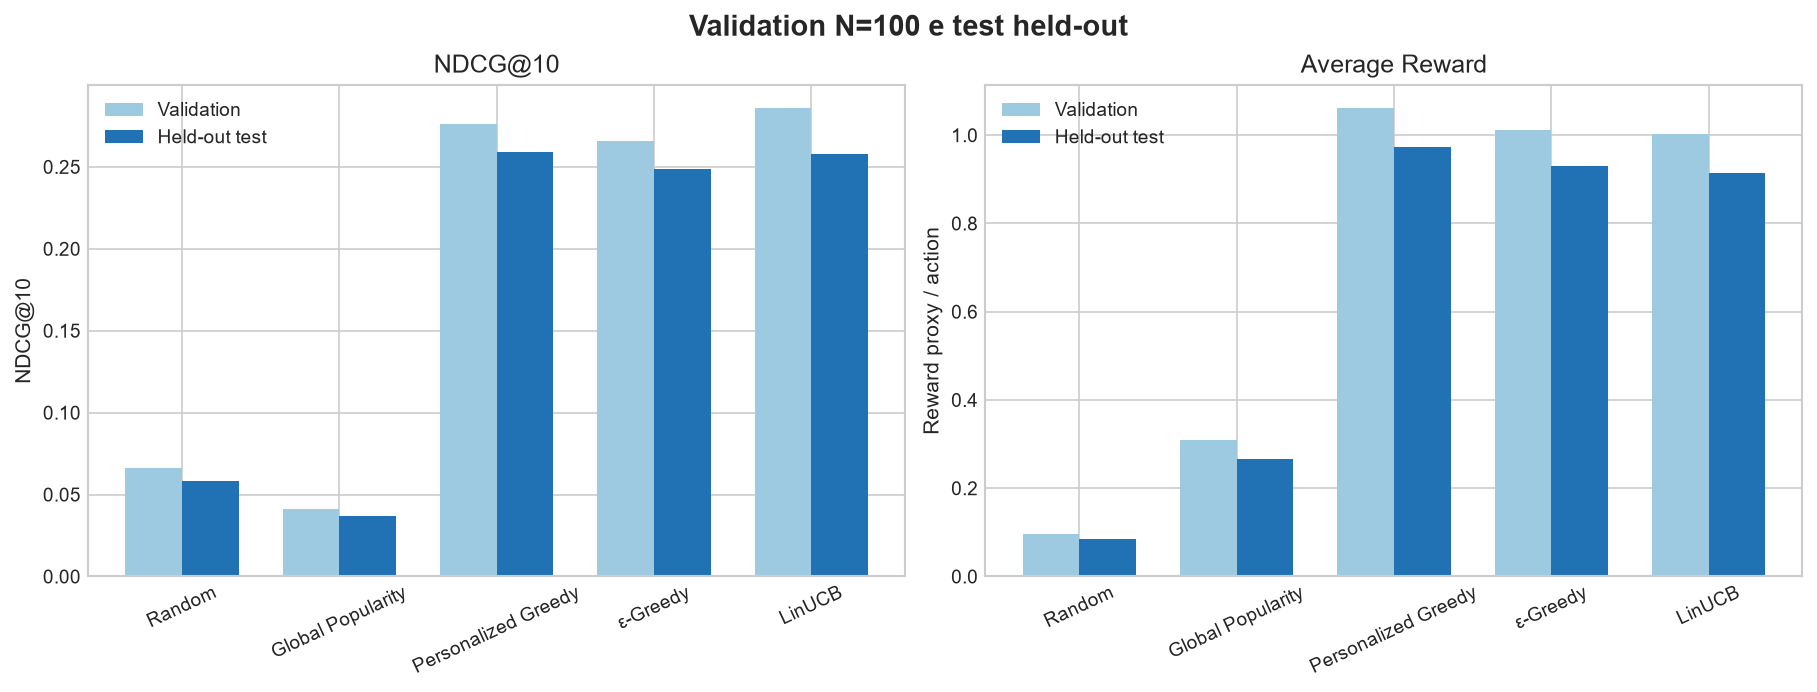

In [4]:
selected=[]
for p,item in manifest['selected_validation_runs'].items():
    g=validation[validation.run_id==item['run_id']]; assert len(g)==1 and g.iloc[0].policy==p and g.iloc[0].candidate_pool_depth==100
    assert json.loads(g.iloc[0].policy_parameters)==item['parameters']
    for metric in ['ndcg@10','average_reward']:
        assert math.isclose(float(g.iloc[0][metric]),float(manifest['validation_scores_at_n100'][p][metric]),rel_tol=0,abs_tol=1e-14)
    assert json.loads(test.loc[test.policy==p,'policy_parameters'].iloc[0])==manifest['final_parameters'][p]
    selected.append(g.iloc[0])
selected=pd.DataFrame(selected)
comp=test.merge(selected,on='policy',suffixes=('_test','_validation'),validate='one_to_one')
for m in ['ndcg@10','average_reward']:
    comp[f'{m}_delta']=comp[f'{m}_test']-comp[f'{m}_validation']
    comp[f'{m}_relative_pct']=100*comp[f'{m}_delta']/comp[f'{m}_validation'].abs().replace(0,np.nan)
rank_v=comp.sort_values('ndcg@10_validation',ascending=False).policy.tolist()
rank_t=comp.sort_values('ndcg@10_test',ascending=False).policy.tolist()
delta_table=comp[['policy','run_id_validation','run_id_test','ndcg@10_validation','ndcg@10_test','ndcg@10_delta','ndcg@10_relative_pct','average_reward_validation','average_reward_test','average_reward_delta','average_reward_relative_pct']].copy()
delta_table['policy']=delta_table.policy.map(LABEL)
display(delta_table.sort_values('ndcg@10_test',ascending=False).style.format({c:'{:.6f}' for c in delta_table.select_dtypes('number').columns}).set_caption('Differenze test − validation'))
print('Ranking validation:', ' > '.join(LABEL[p] for p in rank_v))
print('Ranking test:      ', ' > '.join(LABEL[p] for p in rank_t))
fig,axes=plt.subplots(1,2,figsize=(12,4.5),constrained_layout=True); x=np.arange(len(comp)); w=.36
for ax,m,title,ylabel in [(axes[0],'ndcg@10','NDCG@10','NDCG@10'),(axes[1],'average_reward','Average Reward','Reward proxy / action')]:
    ax.bar(x-w/2,comp[f'{m}_validation'],w,label='Validation',color='#9ecae1')
    ax.bar(x+w/2,comp[f'{m}_test'],w,label='Held-out test',color='#2171b5')
    ax.set(title=title,ylabel=ylabel,xticks=x,xticklabels=[LABEL[p] for p in comp.policy]); ax.tick_params(axis='x',rotation=25); ax.legend()
fig.suptitle('Validation N=100 e test held-out',fontsize=14,fontweight='bold'); plt.show()

## 4. Trade-off accuratezza e scoperta

Ogni punto è una policy con lo stesso candidate-pool depth N=100. La posizione orizzontale rappresenta NDCG@10; gli assi verticali mostrano track novelty, artist novelty e artist ILD @10. I valori sono descrittivi: novelty e diversità più alte non implicano maggiore utilità per l'utente.

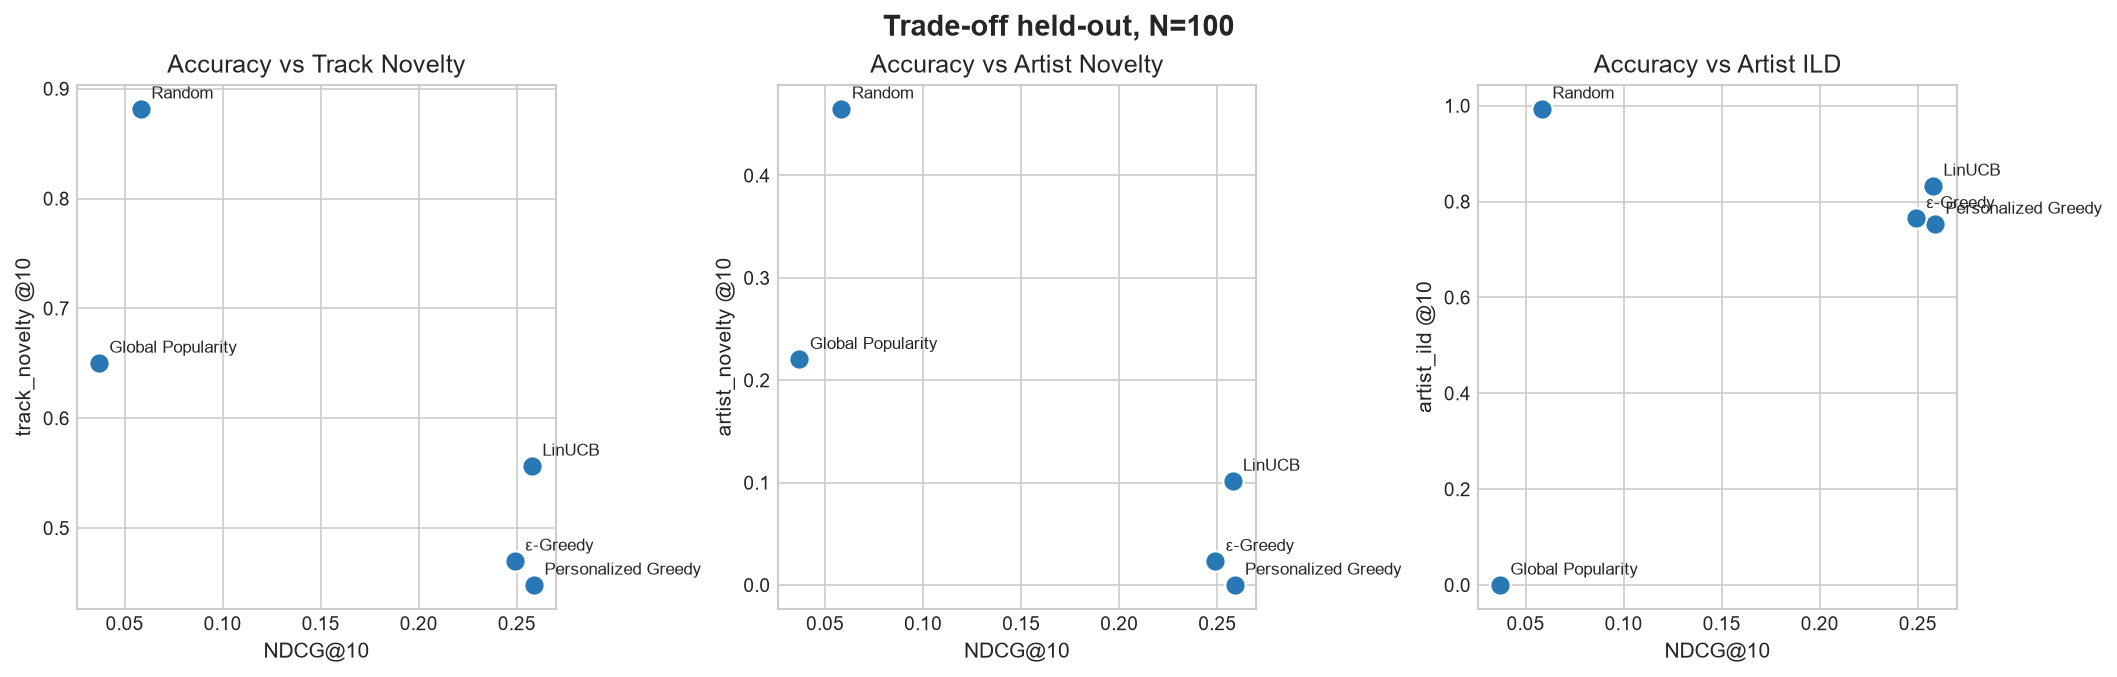

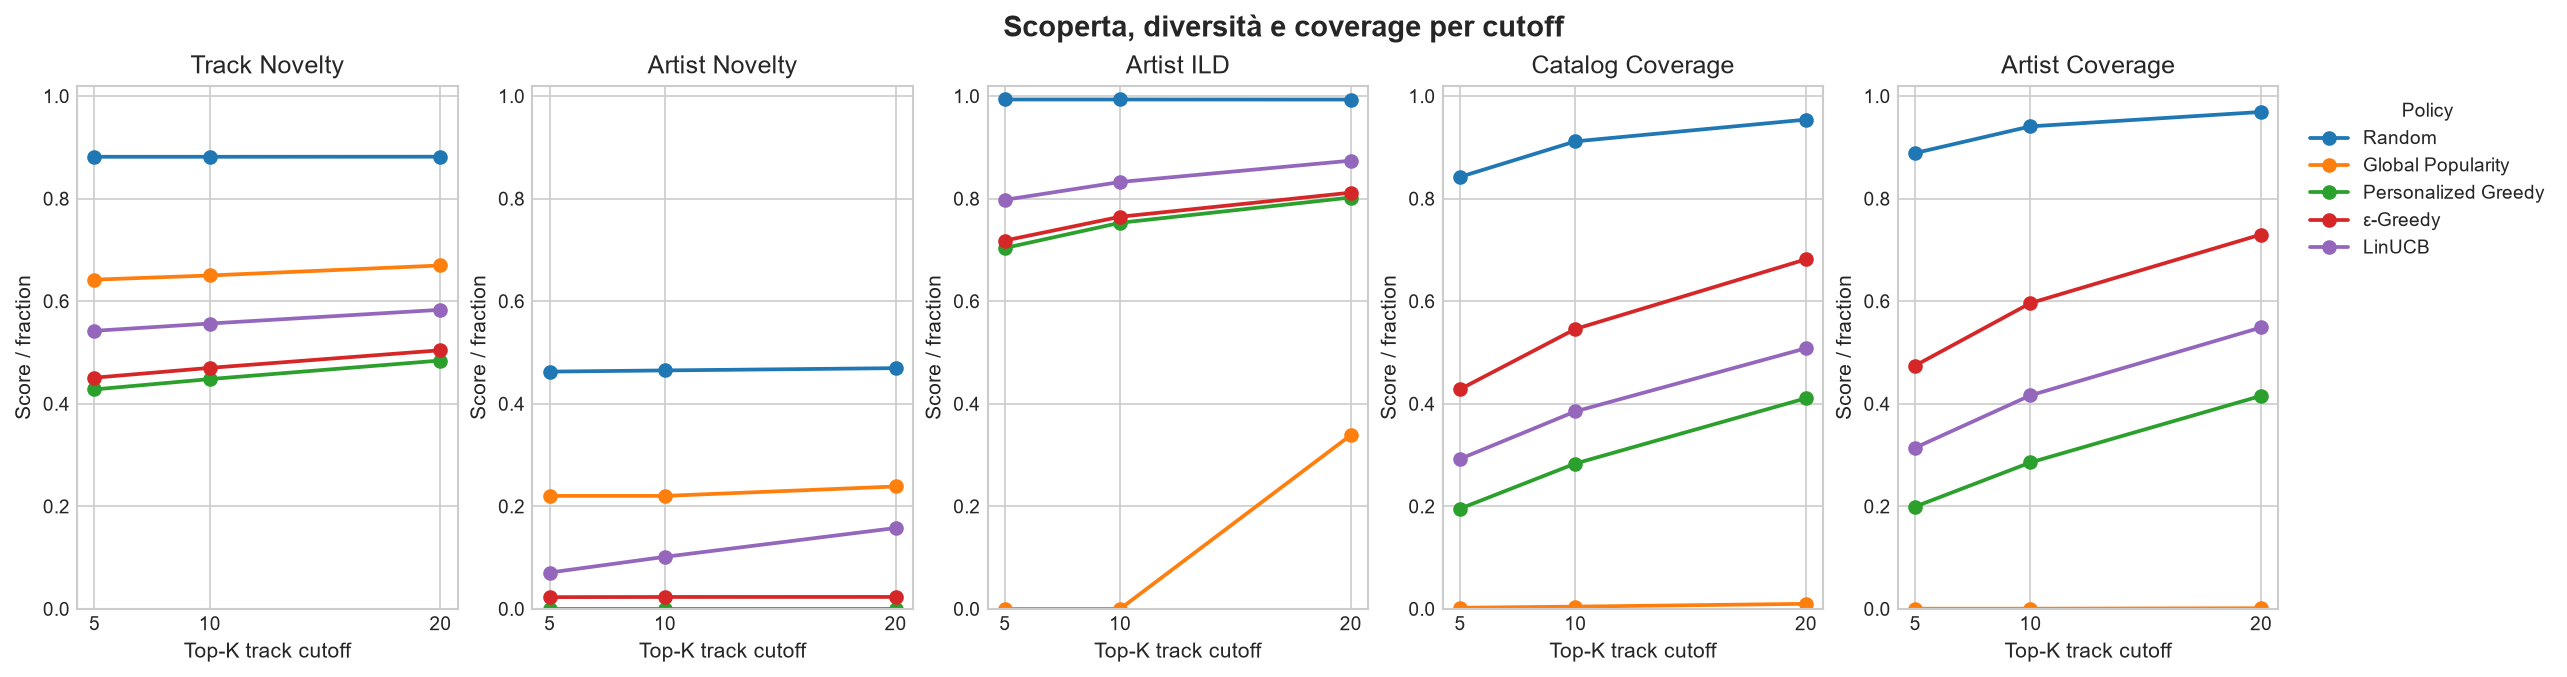

In [5]:
fig,axes=plt.subplots(1,3,figsize=(14,4.4),constrained_layout=True)
for ax,y,title in [(axes[0],'track_novelty@10','Accuracy vs Track Novelty'),(axes[1],'artist_novelty@10','Accuracy vs Artist Novelty'),(axes[2],'artist_ild@10','Accuracy vs Artist ILD')]:
    ax.scatter(test['ndcg@10'],test[y],s=95,c='#2878B5',edgecolor='white',linewidth=1)
    for _,r in test.iterrows(): ax.annotate(r.policy_label,(r['ndcg@10'],r[y]),xytext=(5,5),textcoords='offset points',fontsize=8)
    ax.set(title=title,xlabel='NDCG@10',ylabel=y.replace('@10',' @10'))
fig.suptitle('Trade-off held-out, N=100',fontsize=14,fontweight='bold'); plt.show()

fig,axes=plt.subplots(1,5,figsize=(17,4.4),sharex=True,constrained_layout=True)
for ax,prefix,title in zip(axes,['track_novelty','artist_novelty','artist_ild','catalog_coverage','artist_coverage'],['Track Novelty','Artist Novelty','Artist ILD','Catalog Coverage','Artist Coverage']):
    for _,r in test.iterrows(): ax.plot([5,10,20],[r[f'{prefix}@{k}'] for k in (5,10,20)],marker='o',lw=1.8,label=r.policy_label)
    ax.set(title=title,xlabel='Top-K track cutoff',ylabel='Score / fraction',xticks=[5,10,20],ylim=(0,1.02))
axes[-1].legend(title='Policy',bbox_to_anchor=(1.04,1),loc='upper left')
fig.suptitle('Scoperta, diversità e coverage per cutoff',fontsize=14,fontweight='bold'); plt.show()

## 5. LinUCB rispetto a Personalized Greedy ed ε-Greedy

Il confronto riporta differenze puntuali per NDCG@10, Average Reward, novelty, ILD e coverage @10. Delta positivo significa che LinUCB ha un valore maggiore; per il confronto con Greedy la variazione percentuale di Artist Novelty non è definita perché la baseline vale zero.

In [6]:
lin=test[test.policy=='linucb'].iloc[0]; baselines=test[test.policy.isin(['greedy','epsilon_greedy'])]
cols=['ndcg@10','average_reward','track_novelty@10','artist_novelty@10','artist_ild@10','catalog_coverage@10','artist_coverage@10']
rows=[]
for _,b in baselines.iterrows():
    row={'Comparison':f"LinUCB − {LABEL[b.policy]}"}
    for m in cols:
        d=float(lin[m]-b[m]); row[f'Δ {m}']=d; row[f'Δ% {m}']=100*d/abs(float(b[m])) if b[m] else np.nan
    rows.append(row)
lin_compare=pd.DataFrame(rows)
display(lin_compare.style.format({c:'{:+.6f}' for c in lin_compare.select_dtypes('number').columns}).set_caption('LinUCB α=2.0 meno la baseline, metriche held-out @10'))

,Comparison,Δ ndcg@10,Δ% ndcg@10,Δ average_reward,Δ% average_reward,Δ track_novelty@10,Δ% track_novelty@10,Δ artist_novelty@10,Δ% artist_novelty@10,Δ artist_ild@10,Δ% artist_ild@10,Δ catalog_coverage@10,Δ% catalog_coverage@10,Δ artist_coverage@10,Δ% artist_coverage@10
0,LinUCB − Personalized Greedy,-0.001055,-0.407481,-0.059984,-6.162724,+0.108348,+24.177623,+0.101535,+nan,+0.079533,+10.562794,+0.101647,+35.863672,+0.130823,+45.810056
1,LinUCB − ε-Greedy,+0.008848,+3.554824,-0.016644,-1.789633,+0.086488,+18.401978,+0.078342,+337.783848,+0.067766,+8.861442,-0.160703,-29.444891,-0.179962,-30.176565


## 6. Esempi qualitativi delle raccomandazioni

Questa sezione confronta cinque decision point realmente registrati nel test per Personalized Greedy, ε-Greedy (ε=0.05) e LinUCB (α=2.0). I dettagli sono letti in modo incrementale dai JSONL per configurazione: il file aggregato da 1,34 GB non viene caricato in RAM.

Il JSONL conserva l'utente, il timestamp, il ranking ordinato tramite item key e artist key, i punteggi, il numero di candidati, il reward dell'azione Top-1, la sua disponibilità e il conteggio dei feedback applicati. Non contiene i nomi leggibili, gli ID sorgente originali, i flag di novelty, i source flags dei candidati o gli eventi futuri individuali. Nomi e ID sorgente sono ricondotti al TSV ufficiale con le stesse chiavi canoniche e le stesse regole di parsing del loader; la novelty è ricostruita dalla storia strettamente precedente al decision point.

La selezione è deterministica e non usa reward: si divide la finestra del test in cinque intervalli cronologici contigui; uno per intervallo è scelto rispettivamente per massima divergenza tra le tre liste, massima concordanza, divergenza mediana, massima divergenza Greedy–LinUCB e massima divergenza Greedy–ε-Greedy. La divergenza è uno meno la Jaccard media tra gli insiemi degli artisti distinti nelle Top-10. I pareggi sono risolti per timestamp e poi user ID; si scelgono utenti distinti. Ogni Top-10 resta la lista di dieci track prodotta dalla policy: la deduplicazione per artista serve solo al criterio di composizione e al conteggio degli artisti nuovi.

Le liste e le metriche aggregate restano descrittive. Il reward è il proxy artist-level già definito dal protocollo, non un giudizio causale né una conferma che sia stata ascoltata la track raccomandata.

In [7]:
import mmap
from datetime import datetime, timedelta
from itertools import zip_longest

QUAL_POLICY_ORDER = ("greedy", "epsilon_greedy", "linucb")
QUAL_LABEL = {"greedy": "Personalized Greedy", "epsilon_greedy": "ε-Greedy (ε=0.05)", "linucb": "LinUCB (α=2.0)"}
QUAL_RUN_IDS = {
    policy: str(test.loc[test.policy.eq(policy), "run_id"].iloc[0])
    for policy in QUAL_POLICY_ORDER
}
for policy, run_id in QUAL_RUN_IDS.items():
    marker = by_id[run_id]
    assert marker["completion_status"] == "completed"
    assert marker["identity"]["policy"] == policy
    assert marker["identity"]["candidate_pool_depth"] == 100
    assert marker["identity"]["configuration_hash"] == EXPECTED_CONFIG_HASH
    assert marker["identity"]["dataset_content_hash"] == EXPECTED_DATASET_HASH

assert test.loc[test.policy.isin(QUAL_POLICY_ORDER), "candidate_pool_digest"].nunique() == 1
QUAL_DETAIL_PATHS = {p: CP / f"{rid}.jsonl" for p, rid in QUAL_RUN_IDS.items()}
assert all(path.is_file() for path in QUAL_DETAIL_PATHS.values())

def _json_value_end(mapped_file, start):
    """Find one JSON value boundary while leaving the large file memory-mapped."""
    first = mapped_file[start]
    if first in (ord("{"), ord("[")):
        depth, in_string, escaped = 0, False, False
        pos = start
        while pos < len(mapped_file):
            char = mapped_file[pos]
            pos += 1
            if in_string:
                if escaped:
                    escaped = False
                elif char == ord("\\"):
                    escaped = True
                elif char == ord('"'):
                    in_string = False
                continue
            if char == ord('"'):
                in_string = True
            elif char in (ord("{"), ord("[")):
                depth += 1
            elif char in (ord("}"), ord("]")):
                depth -= 1
                if depth == 0:
                    return pos
        raise ValueError("JSON value in checkpoint is not terminated")
    if first == ord('"'):
        pos, escaped = start + 1, False
        while pos < len(mapped_file):
            char = mapped_file[pos]
            pos += 1
            if escaped:
                escaped = False
            elif char == ord("\\"):
                escaped = True
            elif char == ord('"'):
                return pos
        raise ValueError("JSON string in checkpoint is not terminated")
    pos = start
    while pos < len(mapped_file) and mapped_file[pos] not in b",]} \t\r\n":
        pos += 1
    return pos

def iter_checkpoint_decisions(path):
    """Yield one decision at a time; do not load the per-run JSONL into RAM."""
    with Path(path).open("rb") as stream:
        with mmap.mmap(stream.fileno(), 0, access=mmap.ACCESS_READ) as mapped:
            marker = b'"decisions":['
            start = mapped.find(marker)
            if start < 0:
                raise ValueError(f"Missing decisions array in {Path(path).name}")
            pos = start + len(marker)
            while True:
                while mapped[pos] in b" \t\r\n":
                    pos += 1
                if mapped[pos] == ord("]"):
                    return
                if mapped[pos] != ord("{"):
                    raise ValueError(f"Malformed decision object at byte {pos}")
                end = _json_value_end(mapped, pos)
                yield json.loads(mapped[pos:end])
                pos = end
                while mapped[pos] in b" \t\r\n":
                    pos += 1
                if mapped[pos] == ord(","):
                    pos += 1
                elif mapped[pos] != ord("]"):
                    raise ValueError(f"Malformed decisions array after byte {pos}")

def _artist_jaccard(left, right):
    left, right = set(left), set(right)
    return len(left & right) / len(left | right) if left or right else 1.0

QUAL_PHASE_START = datetime.fromisoformat(config["temporal"]["test_start"])
QUAL_PHASE_END_EXCLUSIVE = datetime.fromisoformat(config["temporal"]["test_end"]) + timedelta(days=1)
QUAL_BUCKET_SECONDS = (QUAL_PHASE_END_EXCLUSIVE - QUAL_PHASE_START).total_seconds() / 5
QUAL_BUCKET_CRITERIA = (
    "massima divergenza tra le tre liste",
    "massima concordanza tra le tre liste",
    "divergenza mediana tra le tre liste",
    "massima divergenza Personalized Greedy–LinUCB",
    "massima divergenza Personalized Greedy–ε-Greedy",
)
qual_buckets = [[] for _ in range(5)]
qual_total_aligned = 0
qual_iterators = [iter_checkpoint_decisions(QUAL_DETAIL_PATHS[p]) for p in QUAL_POLICY_ORDER]
for records_at_time in zip_longest(*qual_iterators, fillvalue=None):
    if all(record is None for record in records_at_time):
        break
    if any(record is None for record in records_at_time):
        raise AssertionError("The three policies contain different decision counts")
    decision_key = (records_at_time[0]["user_id"], records_at_time[0]["decision_time"])
    if any((r["user_id"], r["decision_time"]) != decision_key for r in records_at_time[1:]):
        raise AssertionError(f"Decision alignment differs across policies at {decision_key}")
    if len({r["candidate_count"] for r in records_at_time}) != 1:
        raise AssertionError(f"Candidate pool sizes differ across policies at {decision_key}")
    if any(len(r["top_k_artist_keys"]) < 10 or len(r["top_k_item_keys"]) < 10 for r in records_at_time):
        raise AssertionError(f"A Top-10 list is incomplete at {decision_key}")
    artist_lists = [r["top_k_artist_keys"][:10] for r in records_at_time]
    greedy_artists, epsilon_artists, linucb_artists = artist_lists
    j_ge = _artist_jaccard(greedy_artists, epsilon_artists)
    j_gl = _artist_jaccard(greedy_artists, linucb_artists)
    j_el = _artist_jaccard(epsilon_artists, linucb_artists)
    overall_divergence = 1.0 - (j_ge + j_gl + j_el) / 3.0
    time = datetime.fromisoformat(decision_key[1])
    bucket = min(4, int((time - QUAL_PHASE_START).total_seconds() / QUAL_BUCKET_SECONDS))
    qual_buckets[bucket].append({
        "user_id": decision_key[0], "decision_time": decision_key[1],
        "overall_divergence": overall_divergence,
        "greedy_linucb_divergence": 1.0 - j_gl,
        "greedy_epsilon_divergence": 1.0 - j_ge,
        "jaccard": (j_ge, j_gl, j_el),
    })
    qual_total_aligned += 1

def _time_user(record):
    return record["decision_time"], record["user_id"]

qual_selected = []
for bucket_number, (criterion, bucket_records) in enumerate(zip(QUAL_BUCKET_CRITERIA, qual_buckets), start=1):
    if not bucket_records:
        raise AssertionError(f"No decisions were found in held-out time stratum {bucket_number}")
    if bucket_number == 1:
        ranked = sorted(bucket_records, key=lambda r: (-r["overall_divergence"], *_time_user(r)))
    elif bucket_number == 2:
        ranked = sorted(bucket_records, key=lambda r: (r["overall_divergence"], *_time_user(r)))
    elif bucket_number == 3:
        median = sorted(r["overall_divergence"] for r in bucket_records)[len(bucket_records) // 2]
        ranked = sorted(bucket_records, key=lambda r: (abs(r["overall_divergence"] - median), *_time_user(r)))
    elif bucket_number == 4:
        ranked = sorted(bucket_records, key=lambda r: (-r["greedy_linucb_divergence"], *_time_user(r)))
    else:
        ranked = sorted(bucket_records, key=lambda r: (-r["greedy_epsilon_divergence"], *_time_user(r)))
    candidate = next((r for r in ranked if all(r["user_id"] != old["user_id"] for old in qual_selected)), None)
    if candidate is None:
        raise AssertionError(f"Could not select a distinct user in time stratum {bucket_number}")
    candidate = dict(candidate)
    candidate["criterion"] = criterion
    candidate["time_stratum"] = bucket_number
    qual_selected.append(candidate)

qual_wanted = {(r["user_id"], r["decision_time"]) for r in qual_selected}
qual_detail_records = {key: {} for key in qual_wanted}
for policy in QUAL_POLICY_ORDER:
    for record in iter_checkpoint_decisions(QUAL_DETAIL_PATHS[policy]):
        key = (record["user_id"], record["decision_time"])
        if key not in qual_wanted:
            continue
        qual_detail_records[key][policy] = {
            "user_id": record["user_id"], "decision_time": record["decision_time"],
            "candidate_count": record["candidate_count"],
            "selected_item_key": record["selected_item_key"], "selected_artist": record["selected_artist"],
            "reward": record["reward"], "reward_available_time": record["reward_available_time"],
            "top_k_item_keys": record["top_k_item_keys"][:10],
            "top_k_artist_keys": record["top_k_artist_keys"][:10],
            "top_k_scores": record["top_k_scores"][:10],
            "feedback_applied_before": record["feedback_applied_before"],
            "top_k_effective_size": record["top_k_effective_size"],
        }
for item in qual_selected:
    key = (item["user_id"], item["decision_time"])
    assert set(qual_detail_records[key]) == set(QUAL_POLICY_ORDER)
    assert len({r["candidate_count"] for r in qual_detail_records[key].values()}) == 1
    for policy, record in qual_detail_records[key].items():
        assert record["selected_item_key"] == record["top_k_item_keys"][0]

QUAL_EXAMPLES = []
for index, item in enumerate(qual_selected, start=1):
    QUAL_EXAMPLES.append({**item, "index": index,
        "policies": qual_detail_records[(item["user_id"], item["decision_time"])]})

print(f"Decision point allineati tra policy: {qual_total_aligned:,}")
print("Candidate pool N=100 e digest identici per le tre policy: verificato")
display(pd.DataFrame([
    ("user_id e decision_time", "Sì", "Sessione abbinata tra policy"),
    ("top_k_item_keys e top_k_artist_keys", "Sì", "Chiavi canoniche ordinate; Top-10 delle track"),
    ("selected_item_key, selected_artist, reward", "Sì", "Reward registrato per l'azione Top-1"),
    ("reward_available_time, top_k_scores", "Sì", "Metadati temporali e punteggi del ranking"),
    ("candidate_count, top_k_effective_size, feedback_applied_before", "Sì", "Dimensione pool e feedback applicati"),
    ("Titolo, nome artista, ID sorgente", "No", "Ricondotti al TSV tramite le chiavi canoniche"),
    ("Novelty per candidato e source flags", "No", "Novelty ricostruita dalla history; source flags non disponibili"),
    ("Eventi futuri individuali", "No", "Conteggio dell'artista Top-1 ricostruito dal TSV per verificare reward"),
], columns=["Campo del JSONL", "Disponibile", "Nota"]))
display(pd.DataFrame([
    ("user_id e decision_time", "Sì", "Sessione abbinata tra policy"),
    ("top_k_item_keys e top_k_artist_keys", "Sì", "Chiavi canoniche ordinate; Top-10 delle track"),
    ("selected_item_key, selected_artist, reward", "Sì", "Reward registrato per l'azione Top-1"),
    ("reward_available_time, top_k_scores", "Sì", "Metadati temporali e punteggi del ranking"),
    ("candidate_count, top_k_effective_size, feedback_applied_before", "Sì", "Dimensione pool e feedback applicati"),
    ("Titolo, nome artista, ID sorgente", "No", "Ricondotti al TSV tramite le chiavi canoniche"),
    ("Novelty per candidato e source flags", "No", "Novelty ricostruita dalla history; source flags non disponibili"),
    ("Eventi futuri individuali", "No", "Conteggio dell'artista Top-1 ricostruito dal TSV per verificare reward"),
], columns=["Campo del JSONL", "Disponibile", "Nota"]))
display(pd.DataFrame([{
    "Esempio": x["index"], "Strato temporale": x["time_stratum"],
    "Regola di selezione": x["criterion"], "Utente": f'U{x["index"]:02d}',
    "Timestamp": x["decision_time"], "Divergenza artisti Top-10": x["overall_divergence"],
    "Jaccard G–ε": x["jaccard"][0], "Jaccard G–LinUCB": x["jaccard"][1],
    "Jaccard ε–LinUCB": x["jaccard"][2],
} for x in QUAL_EXAMPLES]).round(3))

Decision point allineati tra policy: 82,905
Candidate pool N=100 e digest identici per le tre policy: verificato


Campo del JSONL,Disponibile,Nota
user_id e decision_time,Sì,Sessione abbinata tra policy
top_k_item_keys e top_k_artist_keys,Sì,Chiavi canoniche ordinate; Top-10 delle track
"selected_item_key, selected_artist, reward",Sì,Reward registrato per l'azione Top-1
"reward_available_time, top_k_scores",Sì,Metadati temporali e punteggi del ranking
"candidate_count, top_k_effective_size, feedback_applied_before",Sì,Dimensione pool e feedback applicati
"Titolo, nome artista, ID sorgente",No,Ricondotti al TSV tramite le chiavi canoniche
Novelty per candidato e source flags,No,Novelty ricostruita dalla history; source flags non disponibili
Eventi futuri individuali,No,Conteggio dell'artista Top-1 ricostruito dal TSV per verificare reward


Campo del JSONL,Disponibile,Nota
user_id e decision_time,Sì,Sessione abbinata tra policy
top_k_item_keys e top_k_artist_keys,Sì,Chiavi canoniche ordinate; Top-10 delle track
"selected_item_key, selected_artist, reward",Sì,Reward registrato per l'azione Top-1
"reward_available_time, top_k_scores",Sì,Metadati temporali e punteggi del ranking
"candidate_count, top_k_effective_size, feedback_applied_before",Sì,Dimensione pool e feedback applicati
"Titolo, nome artista, ID sorgente",No,Ricondotti al TSV tramite le chiavi canoniche
Novelty per candidato e source flags,No,Novelty ricostruita dalla history; source flags non disponibili
Eventi futuri individuali,No,Conteggio dell'artista Top-1 ricostruito dal TSV per verificare reward


Esempio,Strato temporale,Regola di selezione,Utente,Timestamp,Divergenza artisti Top-10,Jaccard G–ε,Jaccard G–LinUCB,Jaccard ε–LinUCB
1,1,massima divergenza tra le tre liste,U01,2009-03-01T11:44:06,1.000,0.0,0.0,0.0
2,2,massima concordanza tra le tre liste,U02,2009-03-14T06:32:40,0.000,1.0,1.0,1.0
3,3,divergenza mediana tra le tre liste,U03,2009-03-27T10:04:41,0.200,1.0,0.7,0.7
4,4,massima divergenza Personalized Greedy–LinUCB,U04,2009-04-09T15:08:15,0.667,1.0,0.0,0.0
5,5,massima divergenza Personalized Greedy–ε-Greedy,U05,2009-04-22T19:25:47,0.833,0.0,0.5,0.0


In [8]:
import csv
import sys
from collections import Counter
from datetime import timedelta
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from src.data.identity import resolve_artist_key, resolve_event_identity_keys
from src.experiments.dataset import _parse_timestamp
QUAL_DATASET = ROOT / config["dataset_path"]
assert QUAL_DATASET.is_file(), f"Dataset TSV not found: {QUAL_DATASET}"
QUAL_REQUIRED_ITEMS = {
    item_key
    for example in QUAL_EXAMPLES
    for row in example["policies"].values()
    for item_key in row["top_k_item_keys"]
}
QUAL_USER_TARGETS = {}
for example in QUAL_EXAMPLES:
    key = (example["user_id"], example["decision_time"])
    QUAL_USER_TARGETS.setdefault(example["user_id"], []).append((key, datetime.fromisoformat(example["decision_time"])))
QUAL_TRACK_IDS, QUAL_FALLBACK_TITLES = set(), set()
for item_key in QUAL_REQUIRED_ITEMS:
    colon = item_key.find(":", 2)
    length = int(item_key[2:colon])
    value = item_key[colon + 1:colon + 1 + length]
    if item_key.startswith("TI"):
        QUAL_TRACK_IDS.add(value)
    elif item_key.startswith("TN"):
        QUAL_FALLBACK_TITLES.add(value)
    else:
        raise ValueError(f"Unexpected canonical item key: {item_key[:20]}")

QUAL_CATALOG = {}
QUAL_HISTORY = { (e["user_id"], e["decision_time"]): set() for e in QUAL_EXAMPLES }
QUAL_FUTURE_COUNTS = { (e["user_id"], e["decision_time"]): Counter() for e in QUAL_EXAMPLES }
qual_rows_read = 0
qual_sample_user_events = 0
with QUAL_DATASET.open("r", encoding="utf-8", errors="replace", newline="") as stream:
    reader = csv.reader(stream, delimiter="\t", quoting=csv.QUOTE_NONE)
    for line_number, row in enumerate(reader, start=1):
        qual_rows_read += 1
        if len(row) != 6:
            raise ValueError(f"Physical TSV row {line_number} has {len(row)} columns; expected 6")
        user_id, timestamp_text, artist_id, artist_name, track_id, track_name = row
        user_id = user_id.strip()
        possible_item = (track_id in QUAL_TRACK_IDS) or (not track_id.strip() and track_name in QUAL_FALLBACK_TITLES)
        is_sample_user = user_id in QUAL_USER_TARGETS
        if not possible_item and not is_sample_user:
            continue
        artist_key = resolve_artist_key(artist_id or None, artist_name or None)
        if possible_item:
            item_key, resolved_artist_key = resolve_event_identity_keys(
                artist_id or None, artist_name or None, track_id or None, track_name or None
            )
            assert resolved_artist_key == artist_key
            if item_key in QUAL_REQUIRED_ITEMS:
                metadata = QUAL_CATALOG.setdefault(item_key, {
                    "artist_key": artist_key, "track_names": Counter(), "artist_names": Counter(),
                    "track_ids": Counter(), "artist_ids": Counter(),
                })
                if metadata["artist_key"] != artist_key:
                    raise AssertionError(f"Canonical item maps to two artists: {item_key}")
                metadata["track_names"][track_name if track_name.strip() else ""] += 1
                metadata["artist_names"][artist_name if artist_name.strip() else ""] += 1
                metadata["track_ids"][track_id if track_id.strip() else ""] += 1
                metadata["artist_ids"][artist_id if artist_id.strip() else ""] += 1
        if is_sample_user:
            qual_sample_user_events += 1
            event_time = _parse_timestamp(timestamp_text)
            for decision_key, decision_time in QUAL_USER_TARGETS[user_id]:
                if event_time < decision_time:
                    QUAL_HISTORY[decision_key].add(artist_key)
                elif decision_time < event_time <= decision_time + timedelta(days=7):
                    QUAL_FUTURE_COUNTS[decision_key][artist_key] += 1
        if qual_rows_read % 5_000_000 == 0:
            print(f"Righe TSV controllate: {qual_rows_read:,}")

assert qual_rows_read > 0
QUAL_MISSING_ITEMS = QUAL_REQUIRED_ITEMS - QUAL_CATALOG.keys()
if QUAL_MISSING_ITEMS:
    print(f"Attenzione: {len(QUAL_MISSING_ITEMS)} item key senza riga catalogo esatta")

def _catalog_values(counter):
    return sorted(value for value in counter if value)

QUAL_REWARD_AUDIT = []
for example in QUAL_EXAMPLES:
    decision_key = (example["user_id"], example["decision_time"])
    for policy, record in example["policies"].items():
        future_count = QUAL_FUTURE_COUNTS[decision_key][record["selected_artist"]]
        reconstructed = math.log1p(future_count)
        logged = float(record["reward"])
        matches = math.isclose(logged, reconstructed, rel_tol=0.0, abs_tol=1e-12)
        QUAL_REWARD_AUDIT.append({
            "Esempio": example["index"], "Policy": QUAL_LABEL[policy],
            "Ascolti futuri dell'artista Top-1 entro 7 giorni": future_count,
            "Reward registrata": logged, "log1p(ascolti)": reconstructed, "Verifica": matches,
        })
assert all(row["Verifica"] for row in QUAL_REWARD_AUDIT), "Logged reward differs from the source-event reconstruction"
print(f"Righe TSV valide lette: {qual_rows_read:,}; record degli utenti selezionati esaminati: {qual_sample_user_events:,}")
print(f"Item con metadati catalogo risolti: {len(QUAL_CATALOG):,}/{len(QUAL_REQUIRED_ITEMS):,}; scan TSV a sei colonne: PASS")
display(pd.DataFrame([
    {"Campo": label, "Item coperti": sum(bool(_catalog_values(meta[field])) for meta in QUAL_CATALOG.values()), "Totale item": len(QUAL_REQUIRED_ITEMS), "Item con valori distinti multipli": sum(len(_catalog_values(meta[field])) > 1 for meta in QUAL_CATALOG.values())}
    for label, field in [("Titoli", "track_names"), ("Nomi artista", "artist_names"), ("Track ID", "track_ids"), ("Artist ID", "artist_ids")]
]))
print("Reward Top-1 ricostruito su (t, t+7 giorni] e confrontato con il JSONL: PASS")
display(pd.DataFrame(QUAL_REWARD_AUDIT).round(6))

Righe TSV valide lette: 19,150,868; record degli utenti selezionati esaminati: 156,734
Item con metadati catalogo risolti: 98/98; scan TSV a sei colonne: PASS
Reward Top-1 ricostruito su (t, t+7 giorni] e confrontato con il JSONL: PASS


Campo,Item coperti,Totale item,Item con valori distinti multipli
Titoli,98,98,0
Nomi artista,98,98,0
Track ID,98,98,0
Artist ID,98,98,0


Esempio,Policy,Ascolti futuri dell'artista Top-1 entro 7 giorni,Reward registrata,log1p(ascolti),Verifica
1,Personalized Greedy,32,3.496508,3.496508,True
1,ε-Greedy (ε=0.05),12,2.564949,2.564949,True
1,LinUCB (α=2.0),0,0.000000,0.000000,True
2,Personalized Greedy,38,3.663562,3.663562,True
2,ε-Greedy (ε=0.05),38,3.663562,3.663562,True
2,LinUCB (α=2.0),17,2.890372,2.890372,True
3,Personalized Greedy,0,0.000000,0.000000,True
3,ε-Greedy (ε=0.05),0,0.000000,0.000000,True
3,LinUCB (α=2.0),33,3.526361,3.526361,True
4,Personalized Greedy,1,0.693147,0.693147,True


### Come leggere gli esempi

Le tabelle mantengono l'ordine track-level del ranking e riportano titolo, artista e ID sorgente quando presenti nel TSV. La colonna “Artista nuovo a t” applica la definizione implementata: l'artista è nuovo se la sua artist key non compare nella storia dell'utente con timestamp `< t`; gli eventi simultanei a `t` non entrano nella storia.

Per ogni decision point mostriamo i brani comuni e i brani specifici delle liste, gli artisti nuovi per policy e il reward Top-1 registrato. Lo scan del TSV ricostruisce anche il numero di ascolti futuri dello stesso artista in `(t, t+7 giorni]`; `log1p` di tale conteggio viene confrontato con il reward del log. Questo riscontro riguarda ascolti dell'artista, non necessariamente del brano raccomandato. Un titolo o nome mancante viene segnalato come tale, senza sostituirlo con metadati dedotti.

In [9]:
from IPython.display import Markdown, display

def _display_catalog_value(values, missing_label):
    names = _catalog_values(values)
    return " / ".join(names) if names else missing_label

for example in QUAL_EXAMPLES:
    index = example["index"]
    key = (example["user_id"], example["decision_time"])
    history = QUAL_HISTORY[key]
    display(Markdown(
        f"### Esempio {index} · utente U{index:02d} · {example['decision_time']}\n\n"
        f"Selezione: **{example['criterion']}**, strato temporale {example['time_stratum']}/5. "
        f"La divergenza è calcolata sulla sovrapposizione Jaccard degli artisti distinti nelle Top-10; "
        f"valore {example['overall_divergence']:.3f}."
    ))
    table_rows = []
    policy_artist_sets = {}
    new_artist_names = {}
    for policy in QUAL_POLICY_ORDER:
        record = example["policies"][policy]
        artists_in_order = []
        for rank, (item_key, artist_key) in enumerate(zip(record["top_k_item_keys"], record["top_k_artist_keys"]), start=1):
            metadata = QUAL_CATALOG.get(item_key)
            if metadata is None:
                track_title, artist_title, raw_track_id, raw_artist_id = (
                    "Titolo non risolto", "Artista non risolto", "—", "—"
                )
            else:
                assert metadata["artist_key"] == artist_key, f"JSONL/catalog artist mismatch for {item_key}"
                track_title = _display_catalog_value(metadata["track_names"], "Titolo assente nel TSV")
                artist_title = _display_catalog_value(metadata["artist_names"], "Nome artista assente nel TSV")
                raw_track_id = _display_catalog_value(metadata["track_ids"], "ID assente; fallback per titolo")
                raw_artist_id = _display_catalog_value(metadata["artist_ids"], "ID assente; fallback per nome")
            is_novel = artist_key not in history
            table_rows.append({
                "Policy": QUAL_LABEL[policy], "Rango": rank,
                "Brano (Last.fm)": track_title, "Artista (Last.fm)": artist_title,
                "Track ID sorgente": raw_track_id, "Artist ID sorgente": raw_artist_id,
                "Artista nuovo a t": "Sì" if is_novel else "No",
            })
            if artist_key not in artists_in_order:
                artists_in_order.append(artist_key)
        policy_artist_sets[policy] = set(record["top_k_artist_keys"])
        new_artist_names[policy] = [
            _display_catalog_value(QUAL_CATALOG[item_key]["artist_names"], "Nome artista assente nel TSV")
            for item_key, artist_key in zip(record["top_k_item_keys"], record["top_k_artist_keys"])
            if artist_key not in history and item_key in QUAL_CATALOG
        ]
    display(pd.DataFrame(table_rows))

    track_lists = {p: set(example["policies"][p]["top_k_item_keys"]) for p in QUAL_POLICY_ORDER}
    common_items = set.intersection(*(track_lists[p] for p in QUAL_POLICY_ORDER))
    exclusive_counts = {p: len(track_lists[p] - set.union(*(track_lists[q] for q in QUAL_POLICY_ORDER if q != p))) for p in QUAL_POLICY_ORDER}
    common_rows = []
    greedy_order = example["policies"]["greedy"]["top_k_item_keys"]
    for item_key in greedy_order:
        if item_key not in common_items:
            continue
        common_rows.append({
            "Brano comune": _display_catalog_value(QUAL_CATALOG[item_key]["track_names"], "Titolo assente nel TSV"),
            **{QUAL_LABEL[p]: example["policies"][p]["top_k_item_keys"].index(item_key) + 1 for p in QUAL_POLICY_ORDER},
        })
    common_summary = ", ".join(f"{QUAL_LABEL[p]}: {exclusive_counts[p]} esclusivi" for p in QUAL_POLICY_ORDER)
    display(Markdown(
        f"**Composizione delle liste:** {len(common_items)} brani comuni a tutte e tre; {common_summary}. "
        f"Gli artisti nuovi in Top-10 sono contati per artist key distinto rispetto agli eventi con timestamp strettamente minore di t."
    ))
    if common_rows:
        display(Markdown("**Brani comuni e posizione nelle liste**"))
        display(pd.DataFrame(common_rows))
    else:
        display(Markdown("Nessun brano è comune alle tre Top-10."))

    reward_rows = []
    for policy in QUAL_POLICY_ORDER:
        record = example["policies"][policy]
        future_count = QUAL_FUTURE_COUNTS[key][record["selected_artist"]]
        top_item = record["selected_item_key"]
        top_meta = QUAL_CATALOG.get(top_item)
        top_artist = (
            _display_catalog_value(top_meta["artist_names"], "Nome artista assente nel TSV")
            if top_meta else "Nome artista non risolto"
        )
        distinct_new_artists = list(dict.fromkeys(new_artist_names[policy]))
        reward_rows.append({
            "Policy": QUAL_LABEL[policy], "Nuovi artisti distinti in Top-10": len(distinct_new_artists),
            "Artisti nuovi (nomi catalogo)": "; ".join(distinct_new_artists) or "Nessuno",
            "Artista Top-1": top_artist, "Reward Top-1 (proxy offline)": record["reward"],
            "Ascolti futuri dello stesso artista in (t,t+7d]": future_count,
        })
    display(pd.DataFrame(reward_rows).round(6))
    new_counts = {policy: row["Nuovi artisti distinti in Top-10"] for policy, row in zip(QUAL_POLICY_ORDER, reward_rows)}
    reward_text = "; ".join(f"{QUAL_LABEL[p]} {example['policies'][p]['reward']:.3f}" for p in QUAL_POLICY_ORDER)
    if example["time_stratum"] == 4:
        local = f"La sovrapposizione artist-level Greedy–LinUCB è {example['jaccard'][1]:.3f}; gli artisti nuovi sono {new_counts['greedy']} per Greedy e {new_counts['linucb']} per LinUCB."
    elif example["time_stratum"] == 5:
        local = f"La sovrapposizione artist-level Greedy–ε-Greedy è {example['jaccard'][0]:.3f}; gli artisti nuovi sono {new_counts['greedy']} per Greedy e {new_counts['epsilon_greedy']} per ε-Greedy."
    else:
        local = (f"Le Jaccard G–ε, G–LinUCB ed ε–LinUCB sono {example['jaccard'][0]:.3f}, "
                 f"{example['jaccard'][1]:.3f} e {example['jaccard'][2]:.3f}. Artisti nuovi: "
                 + "; ".join(f"{QUAL_LABEL[p]} {new_counts[p]}" for p in QUAL_POLICY_ORDER) + ".")
    display(Markdown(
        f"**Lettura locale:** {local} Reward Top-1 registrati (proxy offline): {reward_text}. "
        f"Questa osservazione descrive un solo decision point e non dimostra un vantaggio generale o causale."
    ))

print("Esempi qualitativi renderizzati:", len(QUAL_EXAMPLES), "| utenti distinti:", len({x['user_id'] for x in QUAL_EXAMPLES}))

Esempi qualitativi renderizzati: 5 | utenti distinti: 5


### Esempio 1 · utente U01 · 2009-03-01T11:44:06

Selezione: **massima divergenza tra le tre liste**, strato temporale 1/5. La divergenza è calcolata sulla sovrapposizione Jaccard degli artisti distinti nelle Top-10; valore 1.000.

Policy,Rango,Brano (Last.fm),Artista (Last.fm),Track ID sorgente,Artist ID sorgente,Artista nuovo a t
Personalized Greedy,1,Hurt,Johnny Cash,0b953455-ef5f-4b36-872b-0022aec503d4,d43d12a1-2dc9-4257-a2fd-0a3bb1081b86,No
Personalized Greedy,2,Old Chunk Of Coal,Johnny Cash,008871e7-b8fc-4569-88b9-cbf8ad8ed153,d43d12a1-2dc9-4257-a2fd-0a3bb1081b86,No
Personalized Greedy,3,The L & N Don'T Stop Here Anymore,Johnny Cash,003bcc0f-a93e-4091-8a91-bac85ee2684a,d43d12a1-2dc9-4257-a2fd-0a3bb1081b86,No
Personalized Greedy,4,At The Cross,Johnny Cash,009b2a17-fd6e-4859-b42a-84431de9a958,d43d12a1-2dc9-4257-a2fd-0a3bb1081b86,No
Personalized Greedy,5,The Struwwelpeter Overture,The Tiger Lillies,01203c5c-adb0-4473-b890-0c3cbad5aaa6,3ad4f6ec-253f-4050-8849-ca26266edfb8,No
Personalized Greedy,6,"Hung Over As The Queen In Maida Vale, Part 2",Godspeed You! Black Emperor,007eefca-d0d6-4d76-864d-aef389cd12c3,3648db01-b29d-4ab9-835c-83f6a5068fe4,No
Personalized Greedy,7,Blue Skies Bring Tears,The Smashing Pumpkins,0029c5b5-e614-4939-bd23-4bf8ea6b5bdf,ba0d6274-db14-4ef5-b28d-657ebde1a396,No
Personalized Greedy,8,The Sign,The Mountain Goats,011fe90c-1228-47fa-80b3-7c203ed27f60,9639cd52-c351-4a17-9797-58880e95a7ef,No
Personalized Greedy,9,There Will Always Be An Ireland,The Mountain Goats,00ff9c9d-7266-467e-a401-de29b1ce7ff4,9639cd52-c351-4a17-9797-58880e95a7ef,No
Personalized Greedy,10,High Doses #2,The Mountain Goats,0046bf14-7f67-4eca-8173-e77a6c24fff5,9639cd52-c351-4a17-9797-58880e95a7ef,No


**Composizione delle liste:** 0 brani comuni a tutte e tre; Personalized Greedy: 10 esclusivi, ε-Greedy (ε=0.05): 10 esclusivi, LinUCB (α=2.0): 10 esclusivi. Gli artisti nuovi in Top-10 sono contati per artist key distinto rispetto agli eventi con timestamp strettamente minore di t.

Nessun brano è comune alle tre Top-10.

Policy,Nuovi artisti distinti in Top-10,Artisti nuovi (nomi catalogo),Artista Top-1,Reward Top-1 (proxy offline),"Ascolti futuri dello stesso artista in (t,t+7d]"
Personalized Greedy,0,Nessuno,Johnny Cash,3.496508,32
ε-Greedy (ε=0.05),7,George Harrison; Zero 7; Dissection; Arcade Fire; Bloc Party; Rebelheart; Fear Factory,Tool,2.564949,12
LinUCB (α=2.0),0,Nessuno,Fractal Pattern,0.000000,0


... (23 outputs left out)

**Composizione delle liste:** 0 brani comuni a tutte e tre; Personalized Greedy: 7 esclusivi, ε-Greedy (ε=0.05): 10 esclusivi, LinUCB (α=2.0): 7 esclusivi. Gli artisti nuovi in Top-10 sono contati per artist key distinto rispetto agli eventi con timestamp strettamente minore di t.

Nessun brano è comune alle tre Top-10.

Policy,Nuovi artisti distinti in Top-10,Artisti nuovi (nomi catalogo),Artista Top-1,Reward Top-1 (proxy offline),"Ascolti futuri dello stesso artista in (t,t+7d]"
Personalized Greedy,0,Nessuno,Patrick Wolf,0.000000,0
ε-Greedy (ε=0.05),5,Frédéric Chopin; Ember Swift; P.G. Six; July Skies; ポルノグラフィティ,Frédéric Chopin,0.000000,0
LinUCB (α=2.0),0,Nessuno,Radiohead,3.663562,38


**Lettura locale:** La sovrapposizione artist-level Greedy–ε-Greedy è 0.000; gli artisti nuovi sono 0 per Greedy e 5 per ε-Greedy. Reward Top-1 registrati (proxy offline): Personalized Greedy 0.000; ε-Greedy (ε=0.05) 0.000; LinUCB (α=2.0) 3.664. Questa osservazione descrive un solo decision point e non dimostra un vantaggio generale o causale.

## 7. Conclusioni e limiti

- Il test è un confronto descrittivo delle cinque configurazioni fissate dalla validation; non modifica il modello selezionato.
- La reward usa play futuri dello stesso utente per l'artista Top-1 nella finestra `(t, t+7 giorni]`. Mancando log di esposizione, non è una misura causale e non consente IPS/SNIPS.
- I decision point sono sequenziali e dipendenti nel tempo. Gli aggregati globali non consentono inferenza per utente; i JSONL contengono decision record, ma un bootstrap corretto richiede ricostruire metriche appaiate per utente preservando l'ordine temporale. Non vengono dichiarate significatività o intervalli di confidenza in questo notebook.
- Le metriche di novelty, diversità e coverage descrivono la varietà delle raccomandazioni e non dimostrano che i contenuti siano stati effettivamente ascoltati o apprezzati.

Le conclusioni sostenibili restano limitate a queste policy, al periodo held-out e alla simulazione offline adottata.

In [10]:
print(f'Configurazioni held-out: {len(test)}/5; candidate depth N={test.candidate_pool_depth.unique().tolist()}')
print('Ordinamento NDCG@10:', ' > '.join(LABEL[p] for p in test.sort_values('ndcg@10',ascending=False).policy))
print('La selezione resta quella validation del manifesto; nessun tuning sul test è stato eseguito.')

Configurazioni held-out: 5/5; candidate depth N=[100]
Ordinamento NDCG@10: Personalized Greedy > LinUCB > ε-Greedy > Random > Global Popularity
La selezione resta quella validation del manifesto; nessun tuning sul test è stato eseguito.
